In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import streamlit

print("All libraries imported successfully!")

All libraries imported successfully!


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/bank_customers.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (5000, 12)


,CustomerID,Age,Gender,Geography,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,BalanceCategory
0,10001,56,Male,France,2,53996.32,2,0,0,156360.98,1,Medium
1,10002,69,Male,France,7,182160.58,4,1,0,118273.60,0,High
2,10003,46,Female,Germany,5,161427.59,1,1,1,132022.12,0,High
3,10004,32,Female,Spain,9,246436.18,4,0,0,29775.06,0,High
4,10005,60,Male,Germany,10,53473.93,2,1,0,17578.18,0,Medium


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       5000 non-null   int64  
 1   Age              5000 non-null   int64  
 2   Gender           5000 non-null   str    
 3   Geography        5000 non-null   str    
 4   Tenure           5000 non-null   int64  
 5   Balance          5000 non-null   float64
 6   NumOfProducts    5000 non-null   int64  
 7   HasCrCard        5000 non-null   int64  
 8   IsActiveMember   5000 non-null   int64  
 9   EstimatedSalary  5000 non-null   float64
 10  Exited           5000 non-null   int64  
 11  BalanceCategory  5000 non-null   str    
dtypes: float64(2), int64(7), str(3)
memory usage: 545.2 KB


In [14]:
df.describe()

,CustomerID,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,46.148600,4.939000,124603.864822,2.512000,0.493400,0.487000,105917.168372,0.238000
std,1443.520003,16.325753,3.129543,71355.077750,1.127701,0.500006,0.499881,54552.376356,0.425902
min,10001.000000,18.000000,0.000000,29.660000,1.000000,0.000000,0.000000,10003.900000,0.000000
25%,11250.750000,32.000000,2.000000,63257.897500,1.000000,0.000000,0.000000,59671.537500,0.000000
50%,12500.500000,46.000000,5.000000,124470.735000,3.000000,0.000000,0.000000,106826.200000,0.000000
75%,13750.250000,60.000000,8.000000,184288.980000,4.000000,1.000000,1.000000,152455.125000,0.000000
max,15000.000000,74.000000,10.000000,249973.170000,4.000000,1.000000,1.000000,199995.030000,1.000000


In [15]:
print(df.isnull().sum())
print("Duplicate records:", df.duplicated().sum())

CustomerID         0
Age                0
Gender             0
Geography          0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
BalanceCategory    0
dtype: int64
Duplicate records: 0


Gender
Female    2504
Male      2496
Name: count, dtype: int64


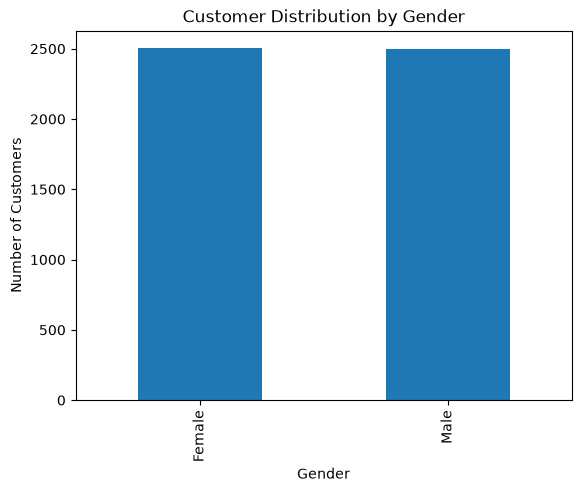

In [16]:
# Cell 1 – Customer gender distribution
gender_counts = df["Gender"].value_counts()

print(gender_counts)

gender_counts.plot(
    kind="bar",
    title="Customer Distribution by Gender"
)

plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

Geography
France     1718
Spain      1657
Germany    1625
Name: count, dtype: int64


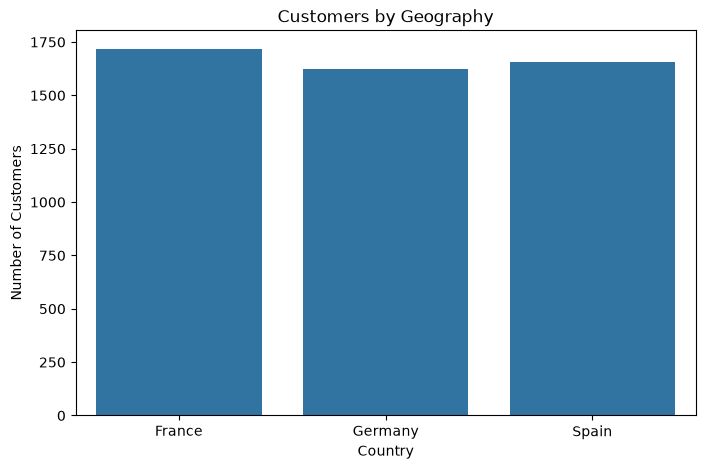

In [17]:
# Cell 2 – Customer distribution by geography
geo_counts = df["Geography"].value_counts()

print(geo_counts)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Geography")

plt.title("Customers by Geography")
plt.xlabel("Country")
plt.ylabel("Number of Customers")
plt.show()

Exited
0    3810
1    1190
Name: count, dtype: int64


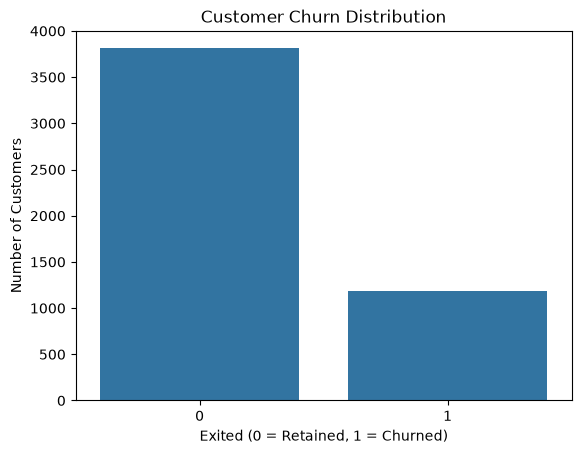

In [18]:
# Cell 3 – Churn distribution
churn_counts = df["Exited"].value_counts()

print(churn_counts)

sns.countplot(data=df, x="Exited")

plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.show()

Geography
France     21.71
Germany    28.00
Spain      21.85
Name: Exited, dtype: float64


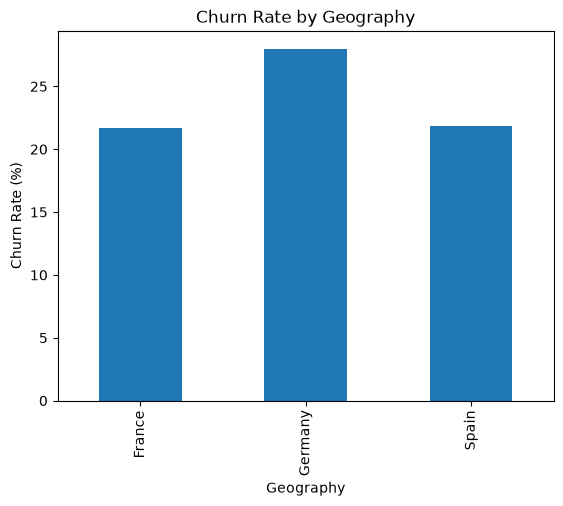

In [19]:
# Cell 4 – Churn percentage by geography
geo_churn = (
    df.groupby("Geography")["Exited"]
    .mean() * 100
)

print(geo_churn.round(2))

geo_churn.plot(
    kind="bar",
    title="Churn Rate by Geography"
)

plt.ylabel("Churn Rate (%)")
plt.show()

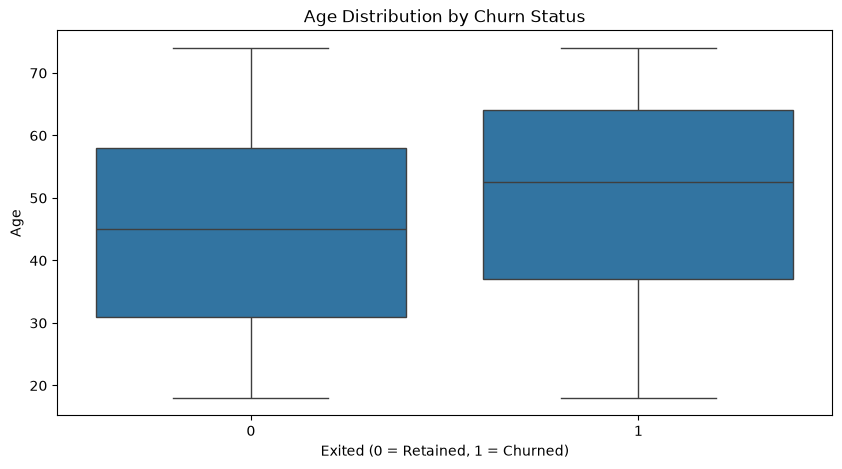

In [20]:
# Cell 5 – Churn by age
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="Age"
)

plt.title("Age Distribution by Churn Status")
plt.xlabel("Exited (0 = Retained, 1 = Churned)")
plt.show()

Exited
0    124822.051496
1    123905.300765
Name: Balance, dtype: float64


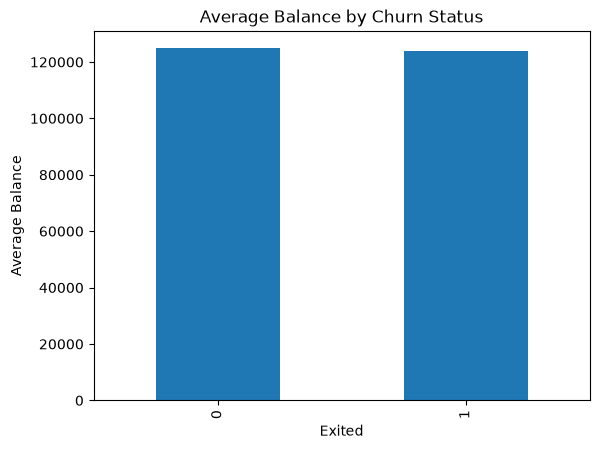

In [21]:
# Cell 6 – Balance analysis
balance_analysis = df.groupby("Exited")["Balance"].mean()

print(balance_analysis)

balance_analysis.plot(
    kind="bar",
    title="Average Balance by Churn Status"
)

plt.ylabel("Average Balance")
plt.show()

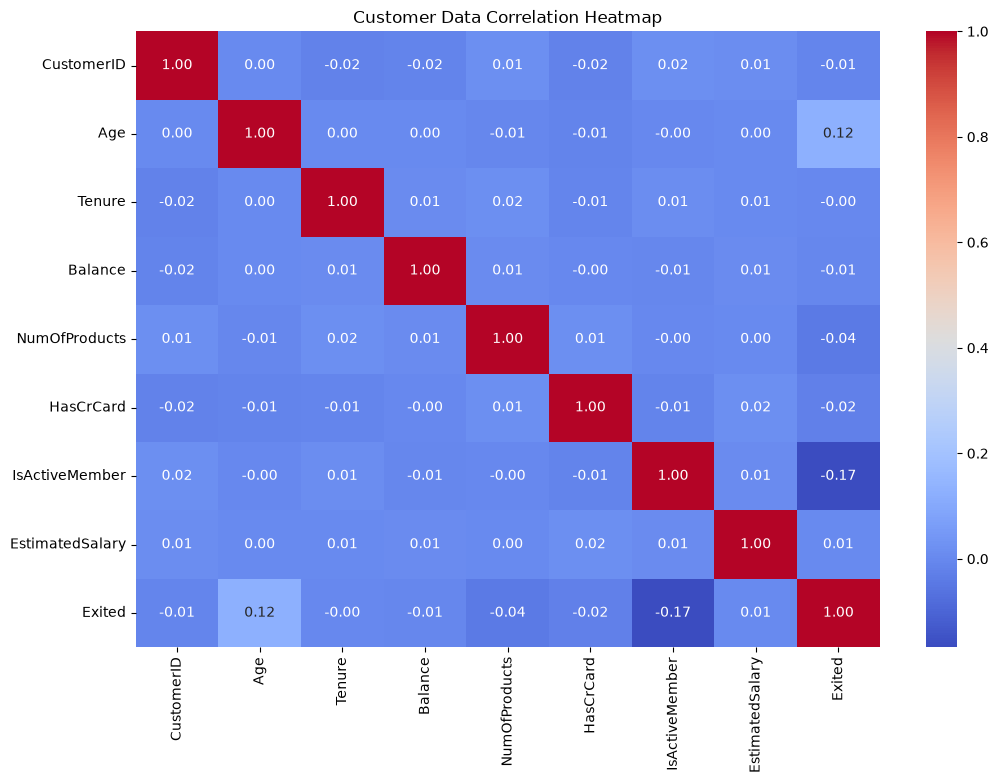

In [22]:
# Cell 7 – Correlation analysis
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Customer Data Correlation Heatmap")
plt.show()

In [23]:
# Creating a business insights summary
total_customers = len(df)
churned = df["Exited"].sum()
retained = total_customers - churned

print("BANK CUSTOMER ANALYSIS")
print("----------------------")
print("Total Customers:", total_customers)
print("Churned Customers:", churned)
print("Retained Customers:", retained)
print("Churn Rate:", round(df["Exited"].mean() * 100, 2), "%")

print("\nHighest Churn Geography:")
print(geo_churn.idxmax())

print("\nAverage Customer Balance:")
print(round(df["Balance"].mean(), 2))

BANK CUSTOMER ANALYSIS
----------------------
Total Customers: 5000
Churned Customers: 1190
Retained Customers: 3810
Churn Rate: 23.8 %

Highest Churn Geography:
Germany

Average Customer Balance:
124603.86


In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [25]:
features = [
    "Age",
    "Balance",
    "EstimatedSalary",
    "Tenure"
]

X = df[features]

X.head()

,Age,Balance,EstimatedSalary,Tenure
0,56,53996.32,156360.98,2
1,69,182160.58,118273.60,7
2,46,161427.59,132022.12,5
3,32,246436.18,29775.06,9
4,60,53473.93,17578.18,10


In [26]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Data standardized successfully!")

Data standardized successfully!


In [27]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["CustomerSegment"] = kmeans.fit_predict(X_scaled)

print("Customer segmentation completed!")
print(df["CustomerSegment"].value_counts().sort_index())

Customer segmentation completed!
CustomerSegment
0    1221
1    1307
2    1219
3    1253
Name: count, dtype: int64


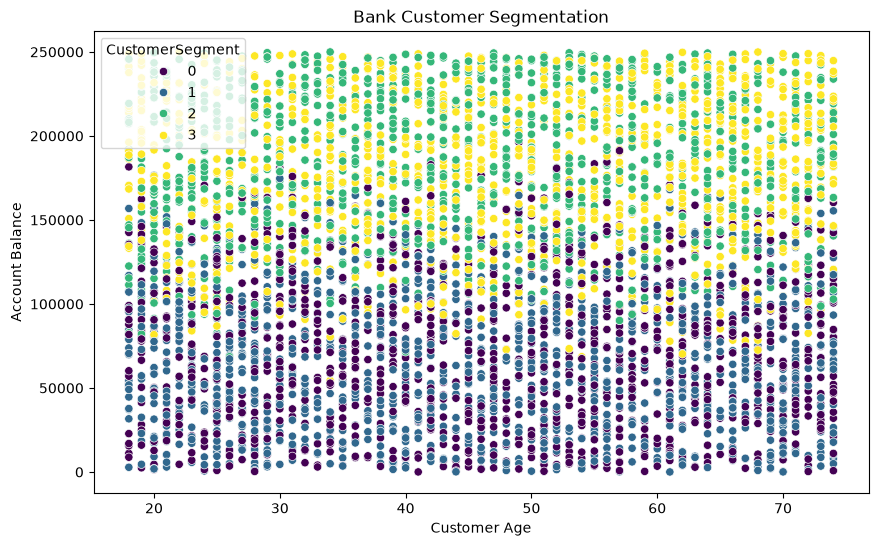

In [28]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Balance",
    hue="CustomerSegment",
    palette="viridis"
)

plt.title("Bank Customer Segmentation")
plt.xlabel("Customer Age")
plt.ylabel("Account Balance")
plt.show()

In [29]:
segment_analysis = df.groupby("CustomerSegment").agg(
    Total_Customers=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Balance=("Balance", "mean"),
    Average_Salary=("EstimatedSalary", "mean"),
    Average_Tenure=("Tenure", "mean"),
    Churn_Rate=("Exited", "mean")
)

segment_analysis["Churn_Rate"] *= 100

segment_analysis.round(2)

,Total_Customers,Average_Age,Average_Balance,Average_Salary,Average_Tenure,Churn_Rate
CustomerSegment,,,,,,
0,1221,46.65,71030.66,52001.37,4.03,23.91
1,1307,45.33,64720.02,153933.34,5.47,24.18
2,1219,44.58,186558.29,118780.87,2.13,22.81
3,1253,48.04,179000.22,95855.87,8.01,24.26


In [30]:
df.to_csv("../data/segmented_bank_customers.csv", index=False)

print("Segmented customer dataset exported successfully!")

Segmented customer dataset exported successfully!
